# 03. Advanced Statistical Visualizations with Seaborn
**Objective:** Generate deep analytical plots (distributions, correlations) using Seaborn with a muted, professional palette.


In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os

os.makedirs('../visualizations/charts', exist_ok=True)

df = pd.read_csv('../data/processed/cleaned_ecommerce_sales.csv')

# Enforce a subtle, cool visual design globally
sns.set_theme(style="darkgrid", palette="muted")


SUCCESS: Automatically identified 'product_category' as the category column.


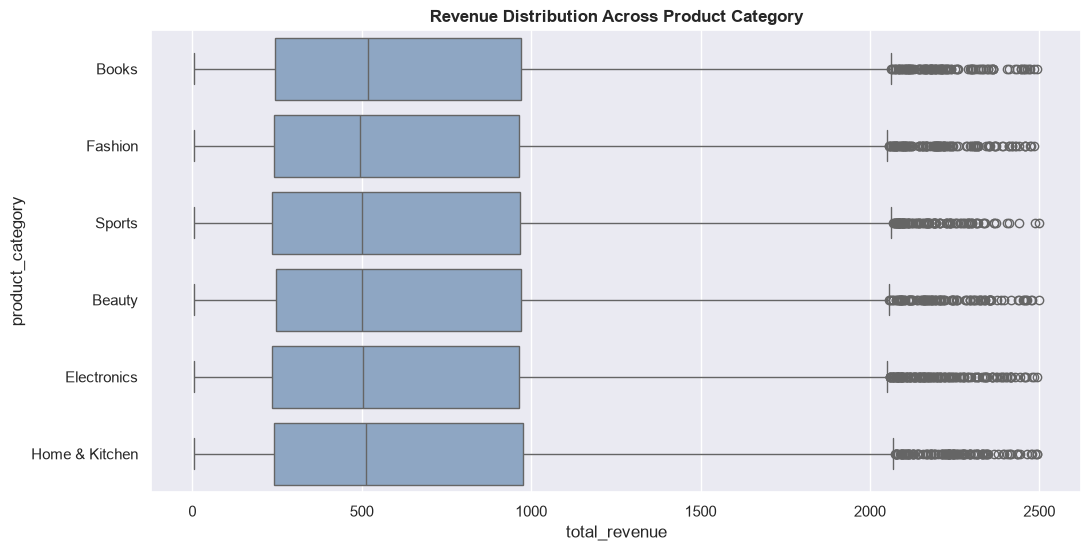

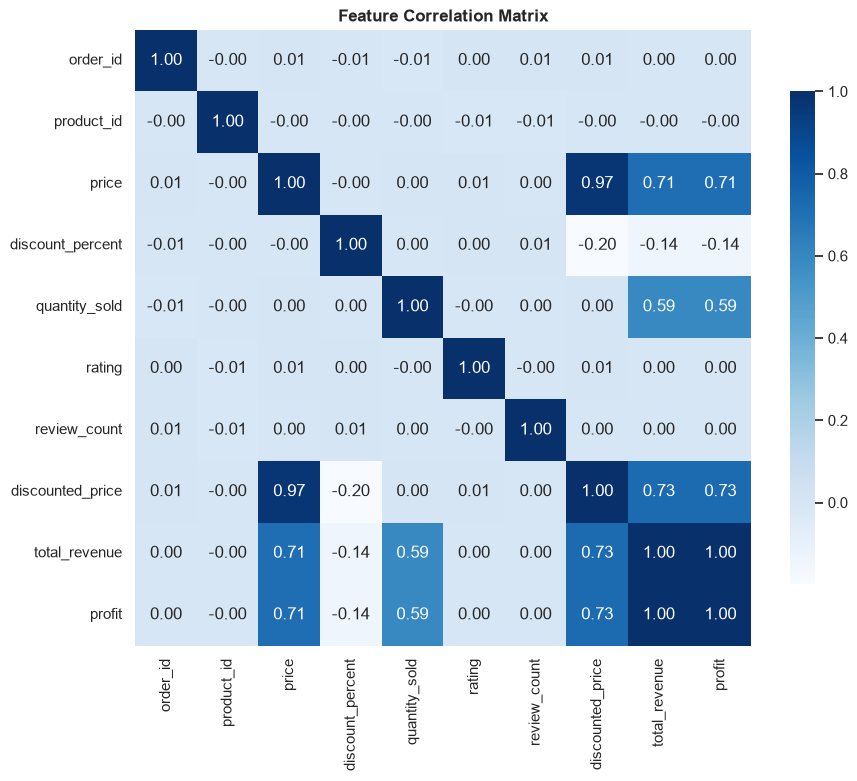

In [5]:
# 1. Revenue Distribution by Category (Boxplot) - DYNAMIC FIX
# This will automatically find your category column instead of guessing.

cat_col = None
possible_names = ['category', 'product_category', 'department', 'item_type', 'segment']

# Check for common category column names first
for name in possible_names:
    if name in df.columns:
        cat_col = name
        break
        
# If standard names fail, forcibly grab the first text (object) column in your dataset
if cat_col is None:
    text_columns = df.select_dtypes(include=['object']).columns
    if len(text_columns) > 0:
        cat_col = text_columns[0]

# Execute the plot if successful
if cat_col and 'total_revenue' in df.columns:
    print(f"SUCCESS: Automatically identified '{cat_col}' as the category column.")
    plt.figure(figsize=(12, 6))
    sns.boxplot(data=df, x='total_revenue', y=cat_col, orient='h', color='#85a5cc')
    
    # Format the title nicely by removing underscores
    clean_title = cat_col.replace('_', ' ').title()
    plt.title(f'Revenue Distribution Across {clean_title}', fontweight='bold')
    
    plt.savefig('../visualizations/charts/revenue_by_category_boxplot.png', dpi=300, bbox_inches='tight')
    plt.show()
else:
    # If this fails, your dataset is fundamentally broken or missing expected data.
    print("CRITICAL ERROR: 'total_revenue' is missing, OR there are zero text columns in your dataset to use as categories.")
    print("Your actual columns are:", df.columns.tolist())


# 2. Correlation Heatmap
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
if len(numeric_cols) > 1:
    plt.figure(figsize=(10, 8))
    sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='Blues', fmt='.2f', 
                cbar_kws={'shrink': .8}, square=True)
    plt.title('Feature Correlation Matrix', fontweight='bold')
    plt.savefig('../visualizations/charts/correlation_heatmap.png', dpi=300, bbox_inches='tight')
    plt.show()